In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder , MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector,make_column_transformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\human-resources-analytics\HR_comma_sep.csv")
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low


In [3]:
X = df.drop('left',axis=1)
y = df['left']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [4]:
# scaler = StandardScaler()
# encoder = OneHotEncoder(sparse_output=False,drop='first')
# ct = make_column_transformer((encoder,make_column_selector(dtype_include='object')),
#                              (scaler,make_column_selector(dtype_include='number')),
#                              verbose_feature_names_out=False)

# scaler = MinMaxScaler()
scaler = StandardScaler()
encoder = OneHotEncoder(sparse_output=False,drop='first')
ct = make_column_transformer((encoder,make_column_selector(dtype_include='object')),
                             ('passthrough',make_column_selector(dtype_include='number')),
                             verbose_feature_names_out=False)

In [5]:
knn = KNeighborsClassifier(n_neighbors=1)
# pipe = Pipeline([('CT',ct),('KNN',knn)])
pipe = Pipeline([('CT',ct),('SCL',scaler),('KNN',knn)])
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('CT', ...), ('SCL', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['satisfaction_level','last_evaluation','number_project',..., 'promotion_last_5years','Department','salary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...), ('passthrough', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generate

In [6]:
y_pred = pipe.predict(X_test)
accuracy_score(y_test,y_pred)

0.9644365414536563

## StandardScaler()

In [7]:
ks = [i for i in range(1,16)]
scores = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipe = Pipeline([('CT',ct),('SCL',scaler),('KNN',knn)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['K','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False).head(5)

,K,Accuracy
0,1,0.964437
1,2,0.960213
2,3,0.948211
3,4,0.946433
5,6,0.945099


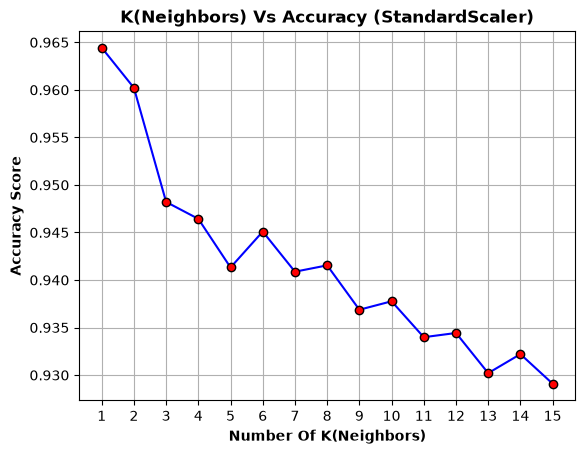

In [8]:
import matplotlib.pyplot as plt

plt.plot(df_scores.K,df_scores.Accuracy,marker='o',color='blue',markerfacecolor='r',markeredgecolor='black')
plt.xticks(df_scores.K)
plt.title('K(Neighbors) Vs Accuracy (StandardScaler)',fontweight='bold')
plt.xlabel('Number Of K(Neighbors)',fontweight='bold')
plt.ylabel('Accuracy Score',fontweight='bold')
plt.grid(True)
plt.show()

## MinMaxScaler()

In [9]:
ks = [i for i in range(1,16)]
scores = []
scaler = MinMaxScaler()
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipe = Pipeline([('CT',ct),('SCL',scaler),('KNN',knn)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['K','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False).head(5)

,K,Accuracy
0,1,0.965548
1,2,0.960213
2,3,0.947322
3,4,0.946433
5,6,0.944210


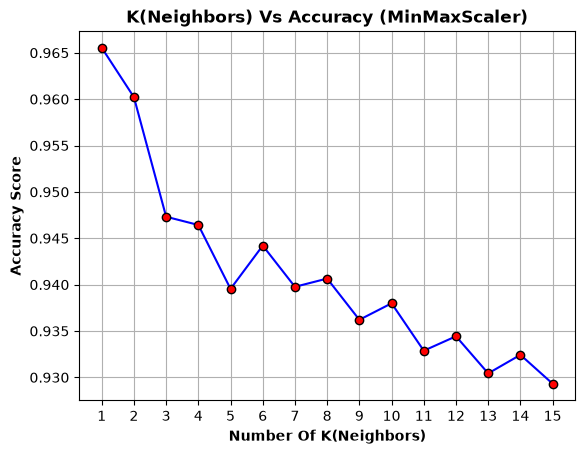

In [10]:
plt.plot(df_scores.K,df_scores.Accuracy,marker='o',color='blue',markerfacecolor='r',markeredgecolor='black')
plt.xticks(df_scores.K)
plt.title('K(Neighbors) Vs Accuracy (MinMaxScaler)',fontweight='bold')
plt.xlabel('Number Of K(Neighbors)',fontweight='bold')
plt.ylabel('Accuracy Score',fontweight='bold')
plt.grid(True)
plt.show()

# Excercise

In [11]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Datasets\loan.csv",index_col=0)
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
Loan_ID,,,,,,,,,,,,
LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [12]:
df.isnull().sum()

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 614 entries, LP001002 to LP002990
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             601 non-null    str    
 1   Married            611 non-null    str    
 2   Dependents         599 non-null    str    
 3   Education          614 non-null    str    
 4   Self_Employed      582 non-null    str    
 5   ApplicantIncome    614 non-null    int64  
 6   CoapplicantIncome  614 non-null    float64
 7   LoanAmount         592 non-null    float64
 8   Loan_Amount_Term   600 non-null    float64
 9   Credit_History     564 non-null    float64
 10  Property_Area      614 non-null    str    
 11  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(7)
memory usage: 62.4+ KB


In [14]:
X , y = df.drop('Loan_Status',axis=1) , df['Loan_Status']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [15]:
from sklearn.impute import SimpleImputer

imputer_cat = SimpleImputer(strategy='most_frequent').set_output(transform='pandas')  # fore category
imputer_num = SimpleImputer().set_output(transform='pandas') # for numeric default strategy=mean

encoder = OneHotEncoder(sparse_output=False,drop='first').set_output(transform='pandas') 

ct_imp = make_column_transformer((imputer_cat,make_column_selector(dtype_include='object')),
                             (imputer_num,make_column_selector(dtype_include='number')),
                             verbose_feature_names_out=False).set_output(transform='pandas') 

ct_cat = make_column_transformer((encoder,make_column_selector(dtype_include='object')),
                             ('passthrough',make_column_selector(dtype_include='number')),
                             verbose_feature_names_out=False).set_output(transform='pandas') 

## StandardScaler()

In [20]:
knn = KNeighborsClassifier(n_neighbors=1)
scaler = StandardScaler()

ks = [i for i in range(1,16)]
scores = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipe = Pipeline([('IMP',ct_imp),('OHE',ct_cat),('SCL',scaler),('KNN',knn)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
    
df_scores = pd.DataFrame(scores,columns=['K','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False).head(5)

,K,Accuracy
6,7,0.843243
5,6,0.843243
7,8,0.843243
10,11,0.837838
9,10,0.837838


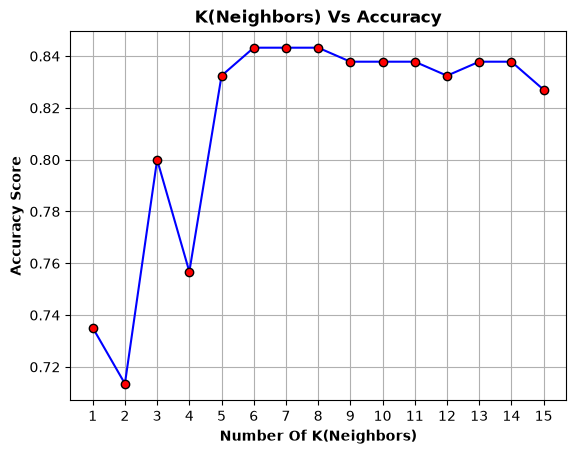

In [21]:
plt.plot(df_scores.K,df_scores.Accuracy,marker='o',color='blue',markerfacecolor='r',markeredgecolor='black')
plt.xticks(df_scores.K)
plt.title('K(Neighbors) Vs Accuracy',fontweight='bold')
plt.xlabel('Number Of K(Neighbors)',fontweight='bold')
plt.ylabel('Accuracy Score',fontweight='bold')
plt.grid(True)
plt.show()

## MinMaxScaler()

In [18]:
knn = KNeighborsClassifier(n_neighbors=1)
scaler = MinMaxScaler()

ks = [i for i in range(1,16)]
scores = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    pipe = Pipeline([('IMP',ct_imp),('OHE',ct_cat),('SCL',scaler),('KNN',knn)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    scores.append([k,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['K','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False).head(5)

,K,Accuracy
4,5,0.821622
5,6,0.821622
7,8,0.821622
6,7,0.810811
2,3,0.805405


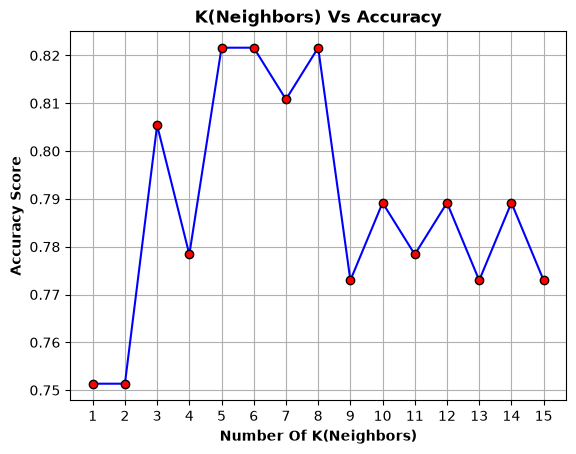

In [19]:
plt.plot(df_scores.K,df_scores.Accuracy,marker='o',color='blue',markerfacecolor='r',markeredgecolor='black')
plt.xticks(df_scores.K)
plt.title('K(Neighbors) Vs Accuracy',fontweight='bold')
plt.xlabel('Number Of K(Neighbors)',fontweight='bold')
plt.ylabel('Accuracy Score',fontweight='bold')
plt.grid(True)
plt.show()